In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.shape

(20640, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

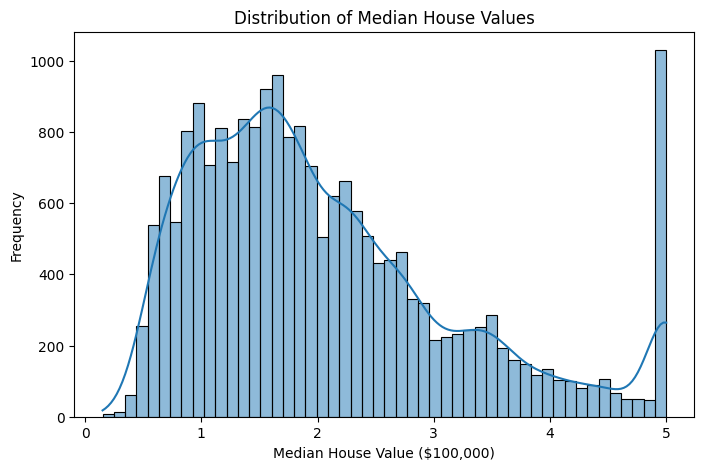

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df['MedHouseVal'], bins=50, kde=True)

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value ($100,000)')
plt.ylabel('Frequency')

plt.show()

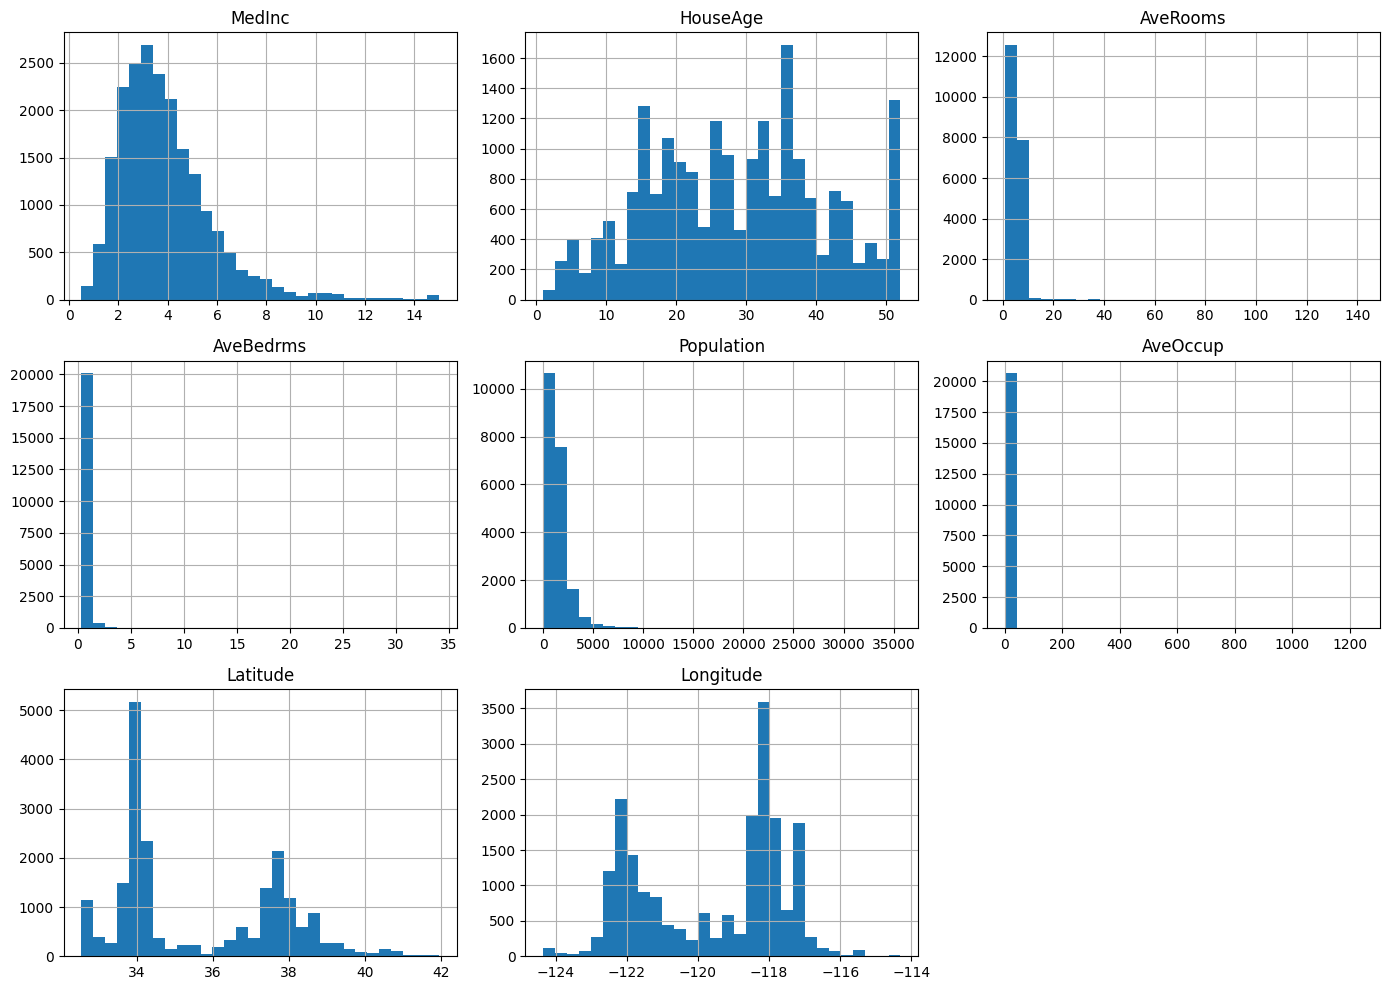

In [8]:
df.drop('MedHouseVal', axis=1).hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

In [9]:
corr_matrix = df.corr()

corr_matrix

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


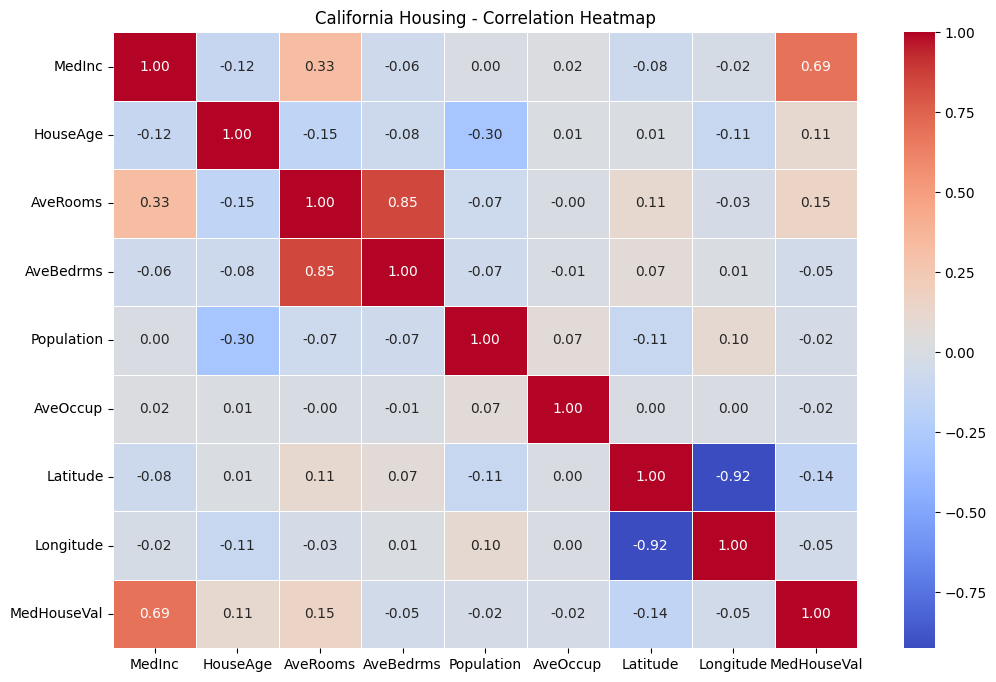

In [10]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('California Housing - Correlation Heatmap')

plt.show()

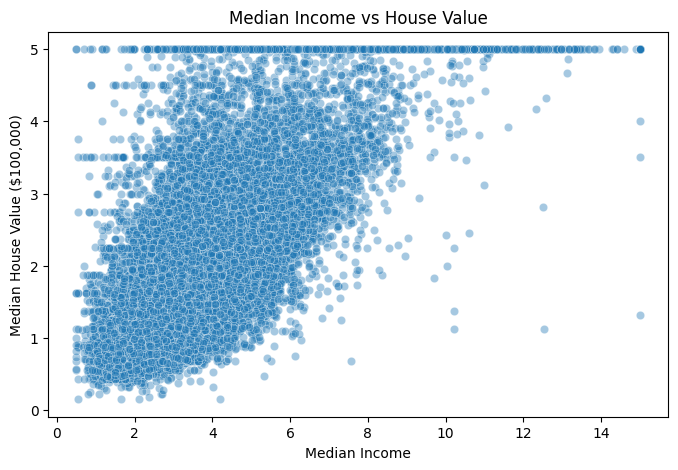

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='MedInc',
    y='MedHouseVal',
    alpha=0.4
)

plt.title('Median Income vs House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value ($100,000)')

plt.show()

In [12]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [13]:
df.isnull().sum().sum()

np.int64(0)

In [14]:
df['RoomsPerHousehold'] = df['AveRooms'] / df['AveOccup']

df['BedroomsPerRoom'] = df['AveBedrms'] / df['AveRooms']

In [15]:
df[['RoomsPerHousehold', 'BedroomsPerRoom']].describe()

,RoomsPerHousehold,BedroomsPerRoom
count,20640.000000,20640.000000
mean,1.976970,0.213075
std,1.146020,0.058023
min,0.002547,0.100000
25%,1.522382,0.175426
50%,1.937936,0.203181
75%,2.296090,0.239834
max,55.222222,1.000000


Task was destroyed but it is pending!
task: <Task pending name='Task-128' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Python314\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-129' coro=<Kernel.shell_main() running at C:\Python314\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Python314\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Python314\Lib\site-packages\cycler\__init__.py:442: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  out[k].append(d[k])
Task was destroyed but it is pending!
task: <Task pending name='Task-129' coro=<Kernel.shell_main() running at C:\Python314\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


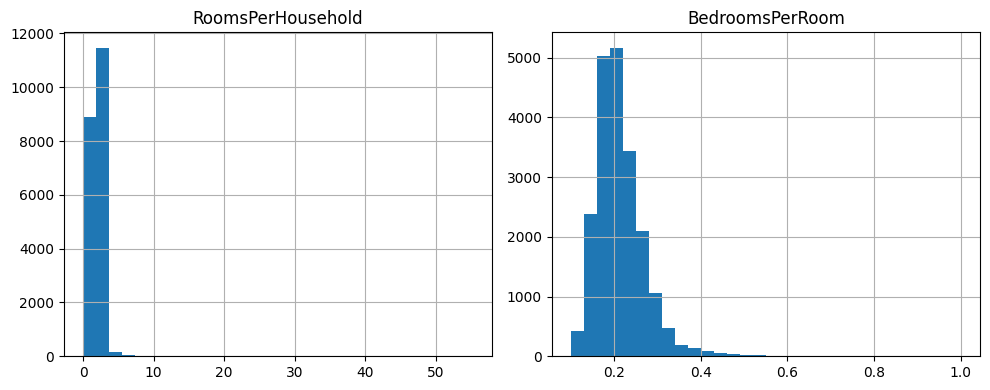

In [16]:
df[['RoomsPerHousehold', 'BedroomsPerRoom']].hist(
    figsize=(10, 4),
    bins=30
)

plt.tight_layout()
plt.show()

In [17]:
df[['RoomsPerHousehold', 'BedroomsPerRoom']].describe()

,RoomsPerHousehold,BedroomsPerRoom
count,20640.000000,20640.000000
mean,1.976970,0.213075
std,1.146020,0.058023
min,0.002547,0.100000
25%,1.522382,0.175426
50%,1.937936,0.203181
75%,2.296090,0.239834
max,55.222222,1.000000


In [18]:
X = df.drop('MedHouseVal', axis=1)

y = df['MedHouseVal']

In [19]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 10)
Target shape: (20640,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [21]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 10)
X_test: (4128, 10)
y_train: (16512,)
y_test: (4128,)


In [22]:
imputer = SimpleImputer(strategy='median')

In [23]:
X_train_imputed = imputer.fit_transform(X_train)

In [24]:
X_test_imputed = imputer.transform(X_test)

In [25]:
print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

print("Missing values in training data:", np.isnan(X_train_imputed).sum())
print("Missing values in testing data:", np.isnan(X_test_imputed).sum())

Training shape: (16512, 10)
Testing shape: (4128, 10)
Missing values in training data: 0
Missing values in testing data: 0


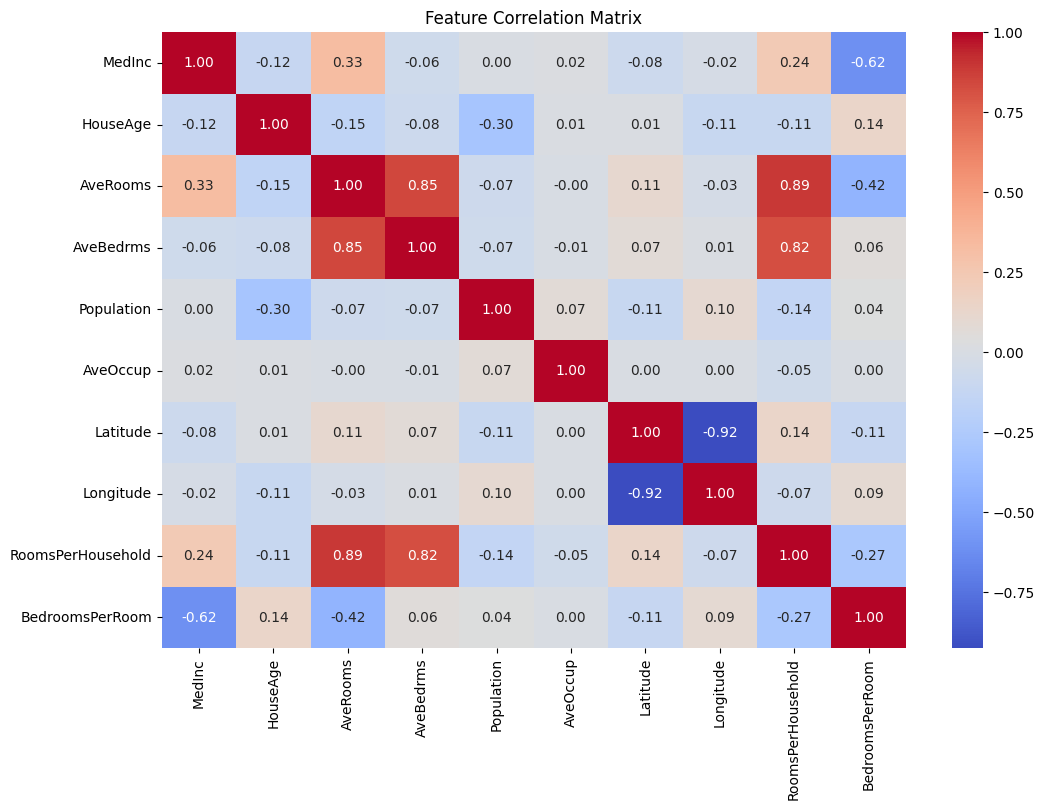

In [26]:
corr_features = X.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_features,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Matrix')

plt.show()

In [27]:
corr_features = X.corr().abs()

upper_triangle = corr_features.where(
    np.triu(np.ones(corr_features.shape), k=1).astype(bool)
)

high_corr_pairs = [
    (column, row, upper_triangle.loc[row, column])
    for column in upper_triangle.columns
    for row in upper_triangle.index
    if upper_triangle.loc[row, column] > 0.8
]

high_corr_pairs

[('AveBedrms', 'AveRooms', np.float64(0.8476213257130424)),
 ('Longitude', 'Latitude', np.float64(0.9246644339150366)),
 ('RoomsPerHousehold', 'AveRooms', np.float64(0.887282474731751)),
 ('RoomsPerHousehold', 'AveBedrms', np.float64(0.8246777913229631))]

In [28]:
scaler = StandardScaler()

In [29]:
X_train_scaled = scaler.fit_transform(X_train_imputed)

In [30]:
X_test_scaled = scaler.transform(X_test_imputed)

In [31]:
print("Training mean:", np.mean(X_train_scaled, axis=0).round(2))

print("Training std:", np.std(X_train_scaled, axis=0).round(2))

Training mean: [-0. -0.  0. -0.  0.  0.  0.  0. -0. -0.]
Training std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [32]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0.79, 0.13,-0.15,...,-0.83, 0.52, 0.24]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.072
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,10
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[221.19,179.12,162.5 ,..., 46.98, 30.27, 20.07]"


In [33]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [34]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression (OLS)")
print("--------------------")
print("MAE:", round(mae_lr, 4))
print("RMSE:", round(rmse_lr, 4))
print("R2 Score:", round(r2_lr, 4))

Linear Regression (OLS)
--------------------
MAE: 0.4862
RMSE: 0.6753
R2 Score: 0.6519


In [35]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [36]:
y_pred_ridge = ridge_model.predict(X_test_scaled)

In [37]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("--------------------")
print("MAE:", round(mae_ridge, 4))
print("RMSE:", round(rmse_ridge, 4))
print("R2 Score:", round(r2_ridge, 4))

Ridge Regression
--------------------
MAE: 0.4862
RMSE: 0.6754
R2 Score: 0.6519


In [38]:
lasso_model = Lasso(alpha=0.01, max_iter=10000)

lasso_model.fit(X_train_scaled, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.01
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [39]:
y_pred_lasso = lasso_model.predict(X_test_scaled)

In [40]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("--------------------")
print("MAE:", round(mae_lasso, 4))
print("RMSE:", round(rmse_lasso, 4))
print("R2 Score:", round(r2_lasso, 4))

Lasso Regression
--------------------
MAE: 0.4908
RMSE: 0.6823
R2 Score: 0.6447


In [41]:
model_results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge', 'Lasso'],
    'MAE': [mae_lr, mae_ridge, mae_lasso],
    'RMSE': [rmse_lr, rmse_ridge, rmse_lasso],
    'R2 Score': [r2_lr, r2_ridge, r2_lasso]
})

model_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.486164,0.675347,0.651945
1,Ridge,0.486164,0.675356,0.651936
2,Lasso,0.490823,0.682316,0.644726


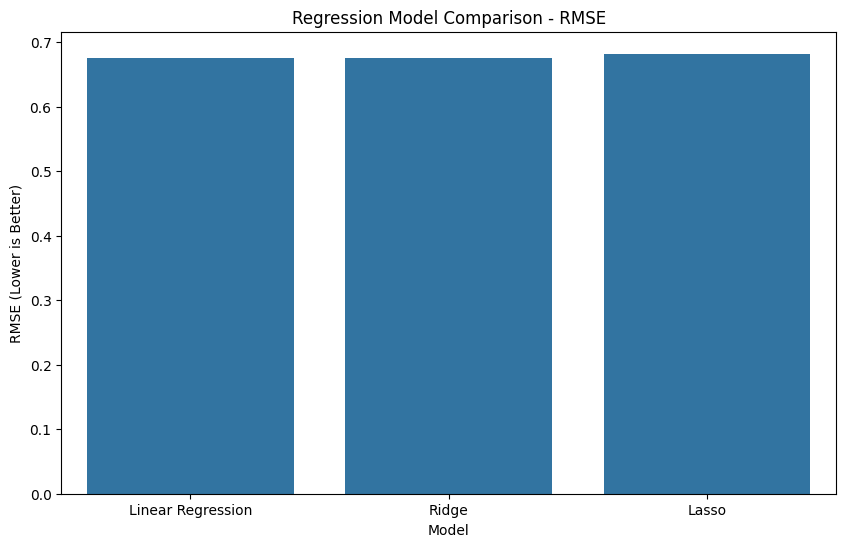

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(data=model_results, x='Model', y='RMSE')

plt.title('Regression Model Comparison - RMSE')
plt.ylabel('RMSE (Lower is Better)')
plt.xlabel('Model')
plt.show()

In [43]:
ridge_params = {
    'alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    Ridge(),
    ridge_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with 

In [44]:
print("Best Ridge Alpha:", ridge_grid.best_params_)

print("Best CV RMSE:", -ridge_grid.best_score_)

Best Ridge Alpha: {'alpha': 10}
Best CV RMSE: 0.6819541681900885


In [45]:
lasso_params = {
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10]
}

In [46]:
lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    lasso_params,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Lasso(max_iter=10000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.0001, 0.001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed durin

In [47]:
print("Best Lasso Alpha:", lasso_grid.best_params_)

print("Best CV RMSE:", -lasso_grid.best_score_)

Best Lasso Alpha: {'alpha': 0.001}
Best CV RMSE: 0.6817623234040224


In [48]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

In [49]:
y_pred_ridge_best = best_ridge.predict(X_test_scaled)

y_pred_lasso_best = best_lasso.predict(X_test_scaled)

In [50]:
print("Tuned Ridge Regression")
print("-------------------")
print("MAE:", round(mean_absolute_error(y_test, y_pred_ridge_best), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_ridge_best)), 4))
print("R2:", round(r2_score(y_test, y_pred_ridge_best), 4))


print("\nTuned Lasso Regression")
print("-------------------")
print("MAE:", round(mean_absolute_error(y_test, y_pred_lasso_best), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_lasso_best)), 4))
print("R2:", round(r2_score(y_test, y_pred_lasso_best), 4))

Tuned Ridge Regression
-------------------
MAE: 0.4862
RMSE: 0.6754
R2: 0.6519

Tuned Lasso Regression
-------------------
MAE: 0.4863
RMSE: 0.6757
R2: 0.6516


In [51]:
final_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge (alpha=1)',
        'Lasso (alpha=0.01)',
        'Tuned Ridge',
        'Tuned Lasso'
    ],
    'MAE': [
        mae_lr,
        mae_ridge,
        mae_lasso,
        mean_absolute_error(y_test, y_pred_ridge_best),
        mean_absolute_error(y_test, y_pred_lasso_best)
    ],
    'RMSE': [
        rmse_lr,
        rmse_ridge,
        rmse_lasso,
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_best)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso_best))
    ],
    'R2': [
        r2_lr,
        r2_ridge,
        r2_lasso,
        r2_score(y_test, y_pred_ridge_best),
        r2_score(y_test, y_pred_lasso_best)
    ]
})

final_results

,Model,MAE,RMSE,R2
0,Linear Regression,0.486164,0.675347,0.651945
1,Ridge (alpha=1),0.486164,0.675356,0.651936
2,Lasso (alpha=0.01),0.490823,0.682316,0.644726
3,Tuned Ridge,0.486168,0.675438,0.651851
4,Tuned Lasso,0.486338,0.675710,0.651571


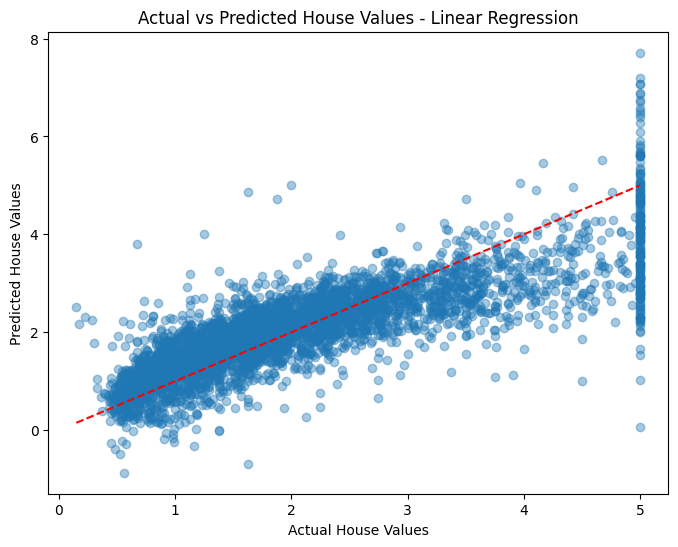

In [52]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lr, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted House Values - Linear Regression')

plt.show()

In [53]:
residuals = y_test - y_pred_lr

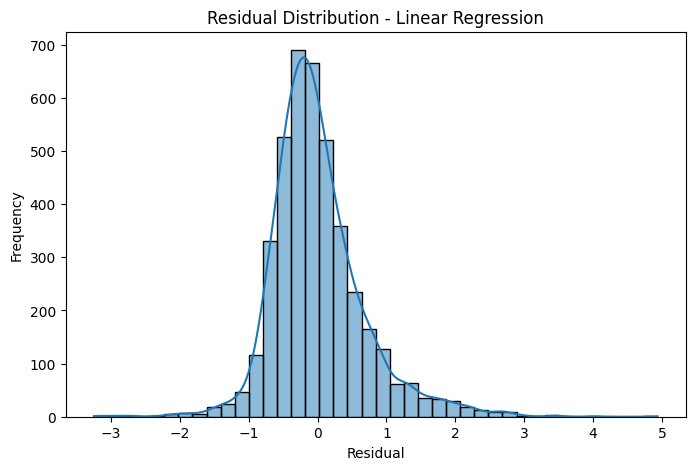

In [54]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=40, kde=True)

plt.title('Residual Distribution - Linear Regression')
plt.xlabel('Residual')
plt.ylabel('Frequency')

plt.show()

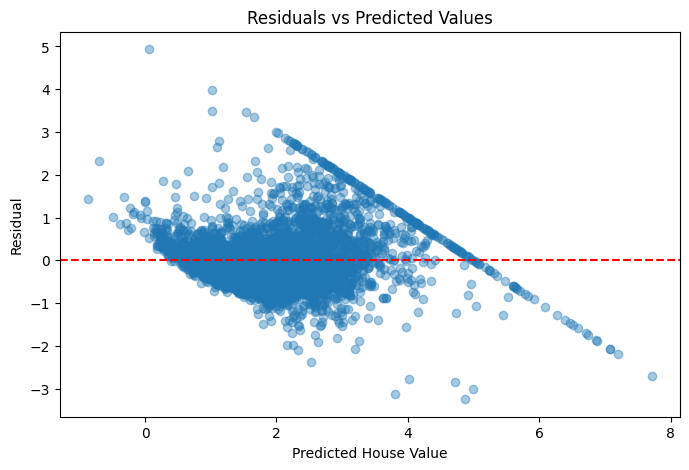

In [55]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred_lr, residuals, alpha=0.4)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted House Value')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted Values')

plt.show()